# Part 7 — Minimum-norm solution of underdetermined systems

From TOML-MIRI *Linear Algebra for Data Science* — exploration exercises (sheet section [1.8.2]).

Exercises in this notebook:

- **7.1** One equation, two unknowns
- **7.2** Reproduce Example 1.13
- **7.3** Gradient descent finds it too

Each exercise keeps the sheet's own parts — **Task**, **Explore**, **Explain** — as far as the sheet defines them. Every identity carries a one-line np.allclose check, and every figure is printed next to the numbers behind it.

## Setup

Shared imports and helpers for the whole notebook. For a wide full row rank matrix, `right_pinv(A) = Aᵀ(AAᵀ)⁻¹` is the right pseudoinverse, `row_projector(A) = Aᵀ(AAᵀ)⁻¹A` is the orthogonal projector onto the row space, and `min_norm_solution(A, b)` returns the solution of `Ax = b` with the smallest norm.

In [1]:
import io

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import HTML, Image as IPyImage, display

np.set_printoptions(precision=4, suppress=True)

TOL = 1e-12


def right_pinv(A):
    """A^+ = A^T (A A^T)^{-1}, the right pseudoinverse of a full row rank A."""
    return A.T @ np.linalg.inv(A @ A.T)


def row_projector(A):
    """Orthogonal projector onto the row space of a full row rank A."""
    return A.T @ np.linalg.inv(A @ A.T) @ A


def min_norm_solution(A, b):
    """The solution of A x = b with the smallest norm."""
    return right_pinv(A) @ b


def line_points(xr, d, c):
    """The points xr + c d, for an array of c."""
    return np.outer(c, d) + xr


def plot_line_circle(ax, r, xr, d, line_label="solution line"):
    """The solution line through xr with direction d, and the circle ||x|| = r."""
    line = line_points(xr, d, np.linspace(-2.0, 2.0, 401))
    ax.plot(line[:, 0], line[:, 1], color="black", lw=2.2, label=line_label)
    ang = np.linspace(0.0, 2.0 * np.pi, 361)
    ax.plot(r * np.cos(ang), r * np.sin(ang), color="royalblue", lw=2.0,
            label="||x||₂ = %.4f" % r)
    ax.plot(0.0, 0.0, "o", color="0.4", ms=5, label="origin")
    ax.plot(xr[0], xr[1], "o", color="crimson", ms=9, zorder=5, label="x_r")
    ax.set_aspect("equal")
    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")
    return ax


print("numpy", np.__version__, "| ipywidgets", widgets.__version__)

numpy 2.5.4 | ipywidgets 8.1.9


## 7.1 — One equation, two unknowns

### Task

One equation in two unknowns, `2x₁ + x₂ = 3`, has a whole line of solutions. Compute the point of smallest norm on that line,

    x_r = Aᵀ (A Aᵀ)⁻¹ b

and plot the solution line, the circle ‖x‖₂ = r (r on a slider) and the point x_r. The static picture uses the radius at which the circle touches the line.

A = [[2. 1.]]   b = [3.]
x_r = (1.2000, 0.6000)   ||x_r|| = 1.341641
distance from the origin to 2x1 + x2 = 3: 1.341641
A x_r = [3.]    A d = [0.]    x_r . d = 0.0e+00


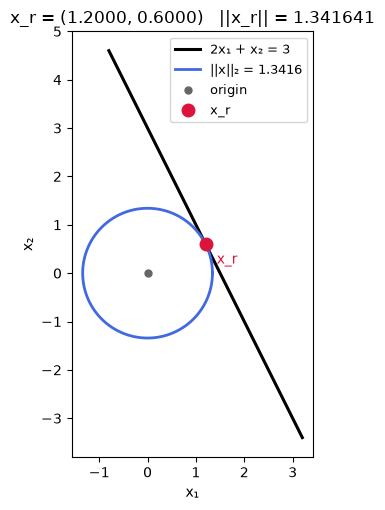

--- checks ---
A x_r = b                          True
x_r = A^T (A A^T)^{-1} b           True
x_r lies on the line               True
x_r . d = 0 (perpendicular)        True
x_r in the row space               True
||x_r|| = distance to the line     True
x_r is the shortest point          True
||(0, 3)|| <= ||x_r||              False   (negative control: on the line, but not the shortest point)


In [2]:
# --- Task: the line 2 x1 + x2 = 3, the circle ||x|| = r and the point x_r ---
A71 = np.array([[2.0, 1.0]])                 # one equation, two unknowns
b71 = np.array([3.0])
xr71 = min_norm_solution(A71, b71)          # A^T (A A^T)^{-1} b
d71 = np.array([1.0, -2.0])                 # direction of the line: A d = 0
r_touch = float(np.linalg.norm(xr71))       # radius at which the circle touches
xr_s = "(%.4f, %.4f)" % (xr71[0], xr71[1])
r_s = "%.6f" % r_touch

print("A =", A71, "  b =", b71)
print("x_r = %s   ||x_r|| = %s" % (xr_s, r_s))
print("distance from the origin to 2x1 + x2 = 3: %.6f" % (3.0 / np.sqrt(5.0)))
print("A x_r =", A71 @ xr71, "   A d =", A71 @ d71,
      "   x_r . d = %.1e" % (xr71 @ d71))

fig, ax = plt.subplots(figsize=(6.2, 5.2))
plot_line_circle(ax, r_touch, xr71, d71, line_label="2x₁ + x₂ = 3")
ax.annotate("x_r", xy=xr71, xytext=(8, -14), textcoords="offset points",
            color="crimson")
ax.legend(loc="upper right", fontsize=9)
ax.set_title("x_r = %s   ||x_r|| = %s" % (xr_s, r_s))
fig.tight_layout()
plt.show()

print("--- checks ---")
checks = {
    "A x_r = b": np.allclose(A71 @ xr71, b71),
    "x_r = A^T (A A^T)^{-1} b": np.allclose(xr71, right_pinv(A71) @ b71),
    "x_r lies on the line": np.allclose(2.0 * xr71[0] + xr71[1], 3.0),
    "x_r . d = 0 (perpendicular)": np.allclose(xr71 @ d71, 0.0),
    "x_r in the row space": np.allclose(row_projector(A71) @ xr71, xr71),
    "||x_r|| = distance to the line": np.allclose(r_touch, 3.0 / np.sqrt(5.0)),
    "x_r is the shortest point": np.allclose(
        np.linalg.norm(line_points(xr71, d71, np.linspace(-2.0, 2.0, 2001)),
                       axis=1).min(), r_touch),
}
for name, ok in checks.items():
    print("%-34s %s" % (name, ok))
print("%-34s %s   (negative control: on the line, but not the shortest point)"
      % ("||(0, 3)|| <= ||x_r||", np.linalg.norm([0.0, 3.0]) <= r_touch))

### Explore

Grow r until the circle first touches the line.

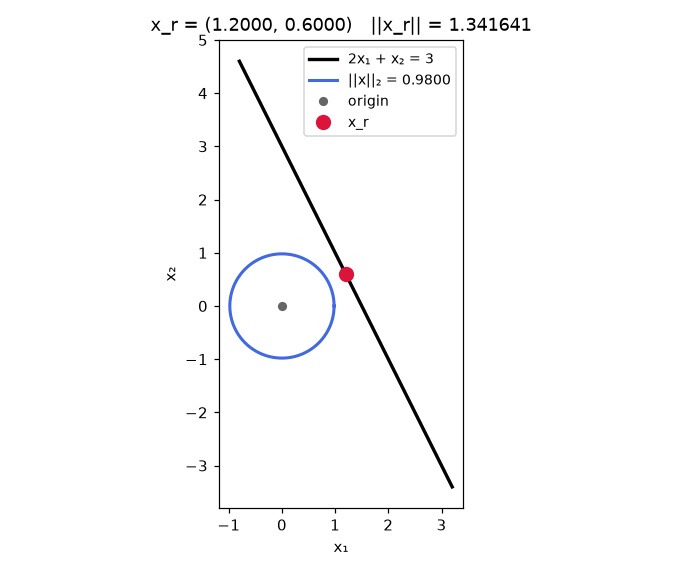

In [ ]:
# --- Explore: grow r until the circle first touches the line ---------------
# The read-out and the picture are shown once and then replaced in place,
# so the output does not blink while the slider moves.
r_slider = widgets.FloatSlider(value=0.5, min=0.0, max=3.0, step=0.01,
                                description="r", continuous_update=True,
                                layout=widgets.Layout(width="380px"))
_handles = {}


def show(key, obj):
    """Display obj once, then update that same output in place."""
    if key in _handles:
        _handles[key].update(obj)
    else:
        _handles[key] = display(obj, display_id="7.1 " + key)


def refresh(*_):
    r = r_slider.value
    if r >= r_touch:
        c_hit = np.sqrt(r ** 2 - r_touch ** 2) / np.linalg.norm(d71)
        hits = line_points(xr71, d71, np.array([c_hit, -c_hit]))
        hits_s = "   x = (%+.4f, %+.4f)  and  (%+.4f, %+.4f)" % (*hits[0], *hits[1])
    else:
        hits, hits_s = None, ""
    show("readout", HTML(
        "<pre>r = %.4f   ||x_r|| = %s   %s%s</pre>"
        % (r, r_s, "the circle touches the line" if r >= r_touch
           else "the circle misses the line", hits_s)))
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    plot_line_circle(ax, r, xr71, d71, line_label="2x₁ + x₂ = 3")
    if hits is not None:
        ax.plot(hits[:, 0], hits[:, 1], "o", color="royalblue", ms=6, zorder=6,
                label="circle meets the line")
    ax.legend(loc="upper right", fontsize=9)
    ax.set_title("x_r = %s   ||x_r|| = %s" % (xr_s, r_s))
    fig.tight_layout()
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110)
    plt.close(fig)
    show("picture", IPyImage(data=buf.getvalue(), format="png"))


display(widgets.VBox([widgets.HTML("<b>Radius r of the circle ||x||₂ = r</b>"),
                      r_slider]))
r_slider.observe(refresh, names="value")
refresh()

### Explain

**Why the touching point is the minimum-norm solution.** The circle ‖x‖₂ = r is the set of points at distance r from the origin, and the line carries every solution of Ax = b. The disc of radius r contains a solution as soon as r reaches the distance from the origin to the line: below that distance the disc misses the line, at that distance the circle is tangent to it, and above it the circle cuts the line in two points of larger norm. The tangency point is therefore the solution with the smallest norm. Algebraically, writing the line as x = x_r + c d with x_r ⊥ d gives

    ‖x‖₂² = ‖x_r‖₂² + c² ‖d‖₂²,

which is smallest at c = 0.

**Why it is perpendicular, and why that is the row space.** The direction d of the line satisfies A d = 0, so d spans N(A), and N(A) = RS(A)⊥. A tangency point is the foot of the perpendicular dropped from the origin, so x_r ⊥ d, that is, x_r ∈ RS(A) — here the single line spanned by the row [2, 1]. The formula of the sheet says the same thing: the minimiser of ½‖x‖₂² under Ax = b has stationarity x = Aᵀλ, so x is a combination of the rows of A, and Ax = b then gives λ = (AAᵀ)⁻¹b, hence

    x_r = Aᵀ(AAᵀ)⁻¹b = (6/5)·[2, 1].

## 7.2 — Reproduce Example 1.13

### Task

Reproduce Example 1.13: for the wide matrix

    A = [ 2  1  0 ]      b = [ 3 ]
        [ 1  3  1 ]          [ 1 ]

compute the minimum-norm solution x_r = Aᵀ(AAᵀ)⁻¹b and the null-space vector x_ns, and plot in 3-D the solution line x_r + c x_ns. Plot also the norm along that line,

    g(c) = ‖x_r + c x_ns‖₂² = ‖x_r‖₂² + c² ‖x_ns‖₂²,

which the sheet asks about in its Explain.

A =
[[2. 1. 0.]
 [1. 3. 1.]]
b = [3. 1.]
x_r = [ 1.5333 -0.0667 -0.3333]
x_ns = [ 1. -2.  5.]
||x_r||_2 = 1.570563   ||x_r||_2^2 = 2.466667   ||x_ns||_2^2 = 30.0


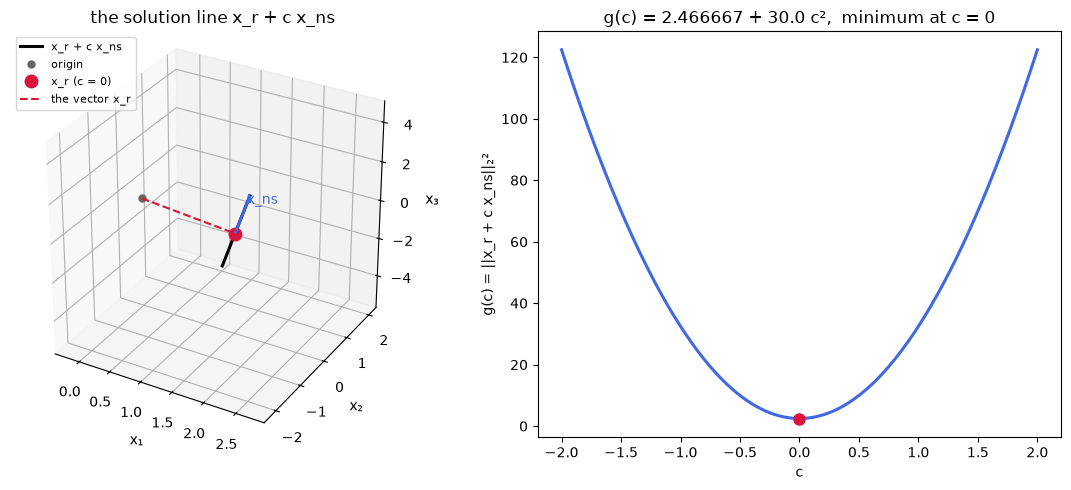

--- checks ---
A x_r = b                              True
A x_ns = 0                             True
x_r^T x_ns = 0                         True
x_r = A^T (A A^T)^{-1} b               True
x_r = (1/30)[46, -2, -10]              True
x_r in the row space                   True
||x_r||_2^2 = 37/15                    True
every x_r + c x_ns solves Ax = b       True
g(c) = ||x_r||^2 + c^2 ||x_ns||^2      True
g is minimal at c = 0                  True
x_r is the shortest solution           True
A x_r = 0                              False   (negative control: x_r is not in N(A))


In [4]:
# --- Task: Example 1.13, x_r, x_ns and the solution line in 3-D -----------
A72 = np.array([[2.0, 1.0, 0.0],
                [1.0, 3.0, 1.0]])              # Example 1.13
b72 = np.array([3.0, 1.0])
xr72 = min_norm_solution(A72, b72)            # A^T (A A^T)^{-1} b
xns72 = np.array([1.0, -2.0, 5.0])            # null-space vector of the sheet
P72 = row_projector(A72)

norm_r = float(np.linalg.norm(xr72))
norm_ns = float(np.linalg.norm(xns72))

print("A ="); print(A72)
print("b =", b72)
print("x_r =", xr72)
print("x_ns =", xns72)
print("||x_r||_2 = %.6f   ||x_r||_2^2 = %.6f   ||x_ns||_2^2 = %.1f"
      % (norm_r, norm_r ** 2, norm_ns ** 2))

c3 = np.linspace(-1.0, 1.0, 201)
line3 = line_points(xr72, xns72, c3)
c = np.linspace(-2.0, 2.0, 401)
g = np.sum(line_points(xr72, xns72, c) ** 2, axis=1)

fig = plt.figure(figsize=(11.4, 5.0))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot(line3[:, 0], line3[:, 1], line3[:, 2], color="black", lw=2.2,
         label="x_r + c x_ns")
ax1.plot([0.0], [0.0], [0.0], "o", color="0.4", ms=5, label="origin")
ax1.plot([xr72[0]], [xr72[1]], [xr72[2]], "o", color="crimson", ms=9,
         label="x_r (c = 0)")
ax1.quiver(xr72[0], xr72[1], xr72[2], *xns72, color="royalblue", lw=2.0,
           arrow_length_ratio=0.08)
ax1.text(*(xr72 + 0.8 * xns72), "x_ns", color="royalblue")
ax1.plot([0.0, xr72[0]], [0.0, xr72[1]], [0.0, xr72[2]], "--", color="crimson",
         lw=1.5, label="the vector x_r")
pts = np.vstack([line3, np.zeros(3)])
lo, hi = pts.min(axis=0) - 0.4, pts.max(axis=0) + 0.4
ax1.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), zlim=(lo[2], hi[2]),
        xlabel="x₁", ylabel="x₂", zlabel="x₃")
ax1.set_box_aspect((1, 1, 1))
ax1.set_title("the solution line x_r + c x_ns")
ax1.legend(loc="upper left", fontsize=8)

ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(c, g, color="royalblue", lw=2.2)
ax2.plot([0.0], [g.min()], "o", color="crimson", ms=8)
ax2.set_xlabel("c")
ax2.set_ylabel("g(c) = ||x_r + c x_ns||₂²")
ax2.set_title("g(c) = %.6f + %.1f c²,  minimum at c = 0"
              % (norm_r ** 2, norm_ns ** 2))
fig.tight_layout()
plt.show()

print("--- checks ---")
checks = {
    "A x_r = b": np.allclose(A72 @ xr72, b72),
    "A x_ns = 0": np.allclose(A72 @ xns72, 0.0),
    "x_r^T x_ns = 0": np.allclose(xr72 @ xns72, 0.0),
    "x_r = A^T (A A^T)^{-1} b": np.allclose(xr72, right_pinv(A72) @ b72),
    "x_r = (1/30)[46, -2, -10]": np.allclose(
        xr72, np.array([46.0, -2.0, -10.0]) / 30.0),
    "x_r in the row space": np.allclose(P72 @ xr72, xr72),
    "||x_r||_2^2 = 37/15": np.allclose(norm_r ** 2, 37.0 / 15.0),
    "every x_r + c x_ns solves Ax = b": np.allclose(
        line_points(xr72, xns72, c) @ A72.T, b72),
    "g(c) = ||x_r||^2 + c^2 ||x_ns||^2": np.allclose(
        g, norm_r ** 2 + c ** 2 * norm_ns ** 2),
    "g is minimal at c = 0": np.allclose(c[np.argmin(g)], 0.0),
    "x_r is the shortest solution": np.allclose(
        np.linalg.norm(line_points(xr72, xns72, c), axis=1).min(), norm_r),
}
for name, ok in checks.items():
    print("%-38s %s" % (name, ok))
print("%-38s %s   (negative control: x_r is not in N(A))"
      % ("A x_r = 0", np.allclose(A72 @ xr72, 0.0)))

### Explain

**Where g is minimised, and why.** The solutions of Ax = b are exactly the points x_r + c x_ns of the plotted line, and x_rᵀ x_ns = 0 makes the cross term vanish when the norm is expanded:

    g(c) = ‖x_r + c x_ns‖₂² = ‖x_r‖₂² + 2c x_rᵀx_ns + c² ‖x_ns‖₂² = 37/15 + 30 c².

The last term is nonnegative and vanishes only at c = 0, so g is minimised at c = 0, at value 37/15 ≈ 2.4667, that is ‖x_r‖₂ ≈ 1.5703. The parabola in the right panel has its vertex exactly at c = 0; the orthogonality x_rᵀ x_ns = 0 is what puts the vertex there, since for a general pair the minimum sits at c = −(x_rᵀx_ns)/‖x_ns‖₂².

**Why x_r is the minimum-norm solution.** Every solution is x_r + c x_ns, so the smallest norm over the solution set is the smallest value of g, attained at c = 0: the minimum-norm solution is x_r itself. It is also the only solution in the row space, because x_ns spans N(A) and N(A) = RS(A)⊥, so x_r + c x_ns lies in RS(A) only when c = 0. Minimising ½‖x‖₂² under Ax = b gives the stationarity condition x = Aᵀλ, and Ax = b then gives λ = (AAᵀ)⁻¹b, which is the formula of the sheet.

## 7.3 — Gradient descent finds it too

### Task

Run gradient descent on the wide matrix of Example 1.13,

    x_{k+1} = x_k − η Aᵀ(Ax_k − b)

starting from x₀ = 0, and plot the iterates in 3-D. The picture also carries the run from x₀ = (1, 0, 0), which is not in the row space of A.

A =
[[2. 1. 0.]
 [1. 3. 1.]]
b = [3. 1.]    x_r = [ 1.5333 -0.0667 -0.3333]
eigenvalues of A^T A = [-0.     2.169 13.831]  (the zero one is the null-space direction)
eta = 0.065071   contraction per step: 0.100000 (fast mode)  0.858857 (slow mode)

k      ||A x_k - b||_2      ||x_k - x_r||_2
    0     3.162278e+00     1.570563e+00
    1     1.834069e+00     1.236684e+00
    2     1.562415e+00     1.060768e+00
    5     9.897140e-01     6.720090e-01
   10     4.625022e-01     3.140358e-01
   20     1.010001e-01     6.857840e-02
   50     1.051832e-03     7.141867e-04
  100     5.223806e-07     3.546929e-07
  200     1.286733e-13     8.756301e-14
  400     4.965068e-16     8.917491e-16

limit from x0 = 0       : [ 1.5333 -0.0667 -0.3333]
||limit - x_r||_2       : 8.92e-16
limit from x0 = (1,0,0) : [ 1.5667 -0.1333 -0.1667]
x_r + (I - P) x0        : [ 1.5667 -0.1333 -0.1667]
||x_r||_2 = 1.570563   ||x_r + (1/30) x_ns||_2 = 1.581139


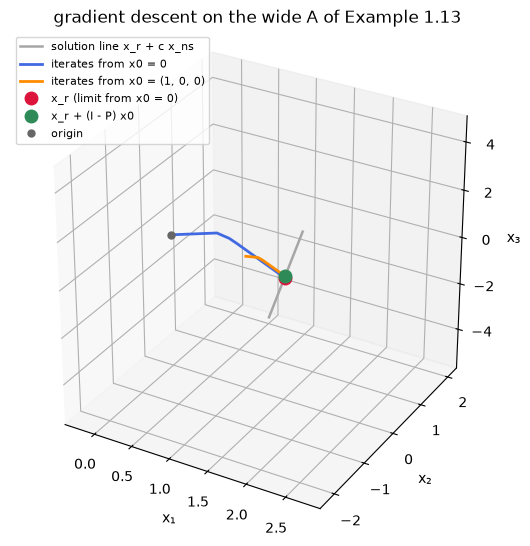

--- checks ---
A x_r = b                                True
the update lies in the row space         True
every iterate from x0 = 0 is in RS(A)    True
the residual decreases                   True
A x_400 = b                              True
x_400 = x_r                              True
the other run keeps x0's null-space part True
the other run stays in x0 + RS(A)        True
P x0 = x0                                False   (negative control: x0 = (1,0,0) is not in the row space)


In [5]:
# --- Task: gradient descent from x0 = 0 on the wide Example 1.13 matrix -----
A73, b73, xr73 = A72, b72, xr72
P73 = row_projector(A73)
lam = np.linalg.eigvalsh(A73.T @ A73)
eta = 0.9 / lam.max()
N_STEPS = 400


def gradient_descent(A, b, x0, eta, n_steps):
    """The iterates of x <- x - eta A^T (A x - b)."""
    xs = [np.array(x0, dtype=float)]
    for _ in range(n_steps):
        xs.append(xs[-1] - eta * (A.T @ (A @ xs[-1] - b)))
    return np.array(xs)


x0_zero = np.zeros(3)
x0_other = np.array([1.0, 0.0, 0.0])
traj_zero = gradient_descent(A73, b73, x0_zero, eta, N_STEPS)
traj_other = gradient_descent(A73, b73, x0_other, eta, N_STEPS)
limit_other = xr73 + (np.eye(3) - P73) @ x0_other

print("A ="); print(A73)
print("b =", b73, "   x_r =", xr73)
lam_pos = lam[lam > TOL * lam.max()]         # the two nonzero eigenvalues
print("eigenvalues of A^T A =", lam, " (the zero one is the null-space direction)")
print("eta = %.6f   contraction per step: %.6f (fast mode)  %.6f (slow mode)"
      % (eta, 1.0 - eta * lam_pos.max(), 1.0 - eta * lam_pos.min()))
print("\nk      ||A x_k - b||_2      ||x_k - x_r||_2")
for k in (0, 1, 2, 5, 10, 20, 50, 100, 200, 400):
    xk = traj_zero[k]
    print("%5d   %14.6e   %14.6e"
          % (k, np.linalg.norm(A73 @ xk - b73), np.linalg.norm(xk - xr73)))

print("\nlimit from x0 = 0       :", traj_zero[-1])
print("||limit - x_r||_2       : %.2e" % np.linalg.norm(traj_zero[-1] - xr73))
print("limit from x0 = (1,0,0) :", traj_other[-1])
print("x_r + (I - P) x0        :", limit_other)
print("||x_r||_2 = %.6f   ||x_r + (1/30) x_ns||_2 = %.6f"
      % (np.linalg.norm(xr73), np.linalg.norm(limit_other)))

fig = plt.figure(figsize=(6.6, 5.6))
ax = fig.add_subplot(projection="3d")
c3 = np.linspace(-1.0, 1.0, 201)
line3 = line_points(xr73, xns72, c3)
ax.plot(line3[:, 0], line3[:, 1], line3[:, 2], color="0.65", lw=1.8,
        label="solution line x_r + c x_ns")
ax.plot(traj_zero[:, 0], traj_zero[:, 1], traj_zero[:, 2], color="royalblue",
        lw=2.0, label="iterates from x0 = 0")
ax.plot(traj_other[:, 0], traj_other[:, 1], traj_other[:, 2], color="darkorange",
        lw=2.0, label="iterates from x0 = (1, 0, 0)")
ax.plot([xr73[0]], [xr73[1]], [xr73[2]], "o", color="crimson", ms=9,
        label="x_r (limit from x0 = 0)")
ax.plot([limit_other[0]], [limit_other[1]], [limit_other[2]], "o",
        color="seagreen", ms=9, label="x_r + (I - P) x0")
ax.plot([0.0], [0.0], [0.0], "o", color="0.4", ms=5, label="origin")
pts = np.vstack([line3, traj_zero, traj_other, np.zeros(3)])
lo, hi = pts.min(axis=0) - 0.4, pts.max(axis=0) + 0.4
ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), zlim=(lo[2], hi[2]),
       xlabel="x₁", ylabel="x₂", zlabel="x₃")
ax.set_box_aspect((1, 1, 1))
ax.set_title("gradient descent on the wide A of Example 1.13")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

print("--- checks ---")
checks = {
    "A x_r = b": np.allclose(A73 @ xr73, b73),
    "the update lies in the row space": np.allclose(
        P73 @ (traj_zero[1] - traj_zero[0]), traj_zero[1] - traj_zero[0]),
    "every iterate from x0 = 0 is in RS(A)": np.allclose(
        traj_zero @ P73.T, traj_zero),
    "the residual decreases": np.all(np.diff(
        np.linalg.norm(traj_zero @ A73.T - b73, axis=1)) <= 1e-15),
    "A x_400 = b": np.allclose(A73 @ traj_zero[-1], b73),
    "x_400 = x_r": np.allclose(traj_zero[-1], xr73),
    "the other run keeps x0's null-space part": np.allclose(
        traj_other[-1], limit_other),
    "the other run stays in x0 + RS(A)": np.allclose(
        (traj_other - x0_other) @ P73.T, traj_other - x0_other),
}
for name, ok in checks.items():
    print("%-40s %s" % (name, ok))
print("%-40s %s   (negative control: x0 = (1,0,0) is not in the row space)"
      % ("P x0 = x0", np.allclose(P73 @ x0_other, x0_other)))

### Explain

**Every update lies in the row space.** The step is x_{k+1} − x_k = −η Aᵀ(Ax_k − b), and Aᵀ maps R^m into the row space of A, so each step is a combination of the rows. Starting from x₀ = 0 the whole trajectory therefore stays in RS(A), the plane spanned by the two rows of A.

**Why that lands on the minimum-norm solution.** The iteration can only stop where Aᵀ(Ax − b) = 0, and Aᵀ is injective here, so Ax = b: the limit is a solution of the system. With x₀ = 0 that solution also lies in RS(A), and among the solutions x_r + c x_ns only x_r itself is in the row space, because x_ns spans N(A) = RS(A)⊥. The limit is therefore x_r, the minimum-norm solution.

**Starting from a nonzero x₀.** The iterates then live in the affine plane x₀ + RS(A), and the limit is x_r + (I − P)x₀, where P = Aᵀ(AAᵀ)⁻¹A projects onto the row space: the component of x₀ orthogonal to the row space is carried along and never removed. For x₀ = (1, 0, 0) that component is (1/30)x_ns, so the run stops at x_r + (1/30)x_ns — a different point of the same solution line, with norm √(37/15 + 1/30) ≈ 1.5811 instead of 1.5703. Only a starting point inside the row space reaches the minimum-norm solution.